# MECHA, 6: along a root

**What you will learn:** solve the water flow in a whole root axis, with sections of different maturity, and see
where along the root the water enters.

**You need:** tutorial 2. **Run time:** about 15 seconds.

## 1. A root axis

A root matures from its tip: near the tip the xylem does not conduct yet; a little further up the endodermis has a
Casparian strip; older parts are suberized. `simulate_root` builds a root of several 5 mm segments, each with its
GRANAP anatomy and its barrier stage (from the collar, at the top, to the tip). It joins their xylem vessels, which
carry the water up to the **collar** (where the root meets the stem), held at −5000 hPa. The soil is at −1000 hPa all
around.

This combines MECHA with what other models would provide: the segments (a root architecture model), their barriers
(a development model) and the soil's potential (a soil model).

In [1]:
import matplotlib.pyplot as plt

from openalea.mecha.simulation import simulate_root

root = simulate_root(barriers=(3, 3, 3, 1, 1, 0), soil_psi=-1000., collar_psi=-5000.)
root

,distance,barrier,xylem_potential,uptake,kr,kr_effective
0,2.5,3,-5000.000000,1.009874e-03,0.000002,0.000002
1,7.5,3,-4995.466680,1.008665e-03,0.000002,0.000002
2,12.5,3,-4990.492262,1.007340e-03,0.000002,0.000002
3,17.5,1,-4984.431945,3.797301e-02,0.000076,0.000076
4,22.5,1,-4981.592907,3.794430e-02,0.000076,0.000076
5,27.5,0,-1000.000000,-1.515996e-15,NaN,NaN


One row per section, from the collar: its `distance` from the collar (mm), its `barrier`, the mean potential of its
xylem (hPa), its `uptake` (cm³ d⁻¹), and two conductivities. `kr` is that of the section alone (as in tutorials
1–5); `kr_effective` is its uptake divided by its surface and by the potential difference it actually sees.

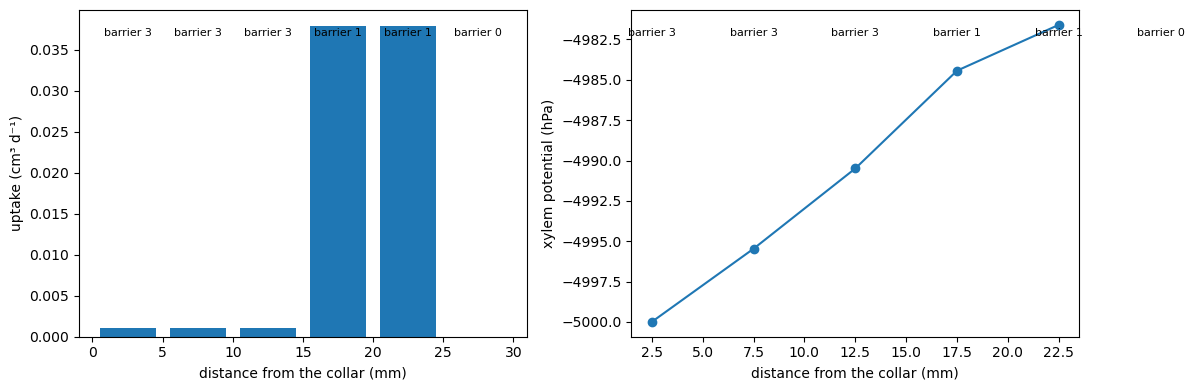

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(root["distance"], root["uptake"], width=4)
axes[0].set_xlabel("distance from the collar (mm)"); axes[0].set_ylabel("uptake (cm³ d⁻¹)")
conducting = root[root["barrier"] > 0]                  # the tip's xylem does not conduct: left out
axes[1].plot(conducting["distance"], conducting["xylem_potential"], "o-")
axes[1].set_xlabel("distance from the collar (mm)"); axes[1].set_ylabel("xylem potential (hPa)")
for ax in axes:
    for distance, barrier in zip(root["distance"], root["barrier"]):
        ax.annotate(f"barrier {barrier}", (distance, 0.92), xycoords=("data", "axes fraction"), ha="center",
                    fontsize=8)
plt.tight_layout()

**Reading it.**

- The young sections with only a Casparian strip (barrier 1) take up most of the water: more than 30 times as much
  as the suberized ones (barrier 3).
- The tip (barrier 0) takes up nothing: its xylem does not conduct yet.
- The xylem's potential changes little along the conducting sections, by about 20 hPa over 2 cm. The vessels
  conduct well, so the sections all see nearly the same pull. (The tip's vessels, which do not conduct, simply take
  the soil's potential: they are left out of the right panel.)

## 2. A drier soil

In [3]:
dry = simulate_root(barriers=(3, 3, 3, 1, 1, 0), soil_psi=-3000., collar_psi=-5000.)
print(f"total uptake: {root['uptake'].sum():.3e} cm³ d⁻¹ in a soil at −1000 hPa, "
      f"{dry['uptake'].sum():.3e} at −3000 hPa")

total uptake: 7.894e-02 cm³ d⁻¹ in a soil at −1000 hPa, 3.947e-02 at −3000 hPa


The difference of potential between the soil and the xylem is halved (2000 instead of 4000 hPa), and so is the
uptake: the flow is proportional to it.

## Going further

In a real simulation, the root grows, its barriers mature with age, and the soil dries where the roots take water.
Each of these comes from another model coupled to MECHA in metafspm. The developer tutorials show how:

- `../developer/02_soil_gradient.ipynb`: a soil drier on one side of a root;
- `../developer/04_full_plant.ipynb`: a whole seedling in its soil, from the water table to the leaves.

## Try it yourself

1. Make the whole root mature (all sections at barrier 3). How much does the uptake fall?
2. Add an exodermal barrier to the young sections (barrier 5 instead of 1).
3. Make the segments longer (`segment_length=1e-2`, in m). Does the xylem's potential still change little?

**Next:** `07_tomato_day_and_night.ipynb`, osmotic potentials.